In [1]:
import numpy as np
import matplotlib.pyplot as plt
import mne
import pandas as pd
from pathlib import Path

Fs = 500
DATA_FOLDER = Path("data/calculia")
RESULTS_FOLDER = Path("results")

# Channel names
CHANNELS = {
    "ANT_FRONTAL" : ["Fp1", "Fp2"],
    "FRONTAL" : ["F3", "F4", "Fz", "F7", "F8"],
    "CENTRAL" : ["C3", "C4", "Cz"],
    "PARIETAL" : ["P3", "P4", "Pz"],
    "OCCIPITAL" : ["O1", "O2"],
    "TEMPORAL" : ["T3", "T4", "T5", "T6"],
}

all_channels = []
for chs in CHANNELS.values():
    all_channels += chs
CHANNELS["ALL_CHANNELS"] = all_channels
CHANNELS["ALL_FRONTAL"] = CHANNELS["ANT_FRONTAL"] + CHANNELS["FRONTAL"]

In [2]:
import matplotlib.font_manager as fm

BG_COLOR = "#f5f5f0"
CAPTION_COLOR = "#222222"
SUPPORT_COLOR = "#666666"

INTER_FONT_PATH = "data\\font\\Inter-Regular.ttf"   # a list of .ttf paths
fm.fontManager.addfont(INTER_FONT_PATH)
plt.rcParams.update({
    "figure.facecolor": BG_COLOR,
    "axes.facecolor": BG_COLOR,
    "text.color": CAPTION_COLOR,
    "axes.labelcolor": SUPPORT_COLOR,
    "xtick.color": SUPPORT_COLOR,
    "ytick.color": SUPPORT_COLOR,
    "figure.dpi": 110,
    "savefig.dpi": 600,
    "font.family": ["Inter", "DejaVu Sans"],
    "axes.spines.top": False,
    "axes.spines.right": False,
})

In [3]:
from _functions import PCE_by_band

PCEs = []

for sbj_id in range(36):
    sbj = f"Subject{sbj_id:02d}"
    rest_raw = mne.io.read_raw_edf(DATA_FOLDER / f"{sbj}_1.edf", verbose=False)
    calc_raw = mne.io.read_raw_edf(DATA_FOLDER / f"Subject{sbj_id:02d}_2.edf", verbose=False)


    for name, channels in CHANNELS.items():           
        rest_np = np.array(rest_raw[["EEG " + ch for ch in channels]][0])
        rest = PCE_by_band(rest_np, Fs = Fs, window_size=10)
        for result in rest:
            PCEs.append({
                "Subject" : sbj,
                "Location" : name,
                "Band" : result["band"],
                "Rest" : 1,
                "PCE" : result["PCE"]
            }) 

        calc_np = np.array(calc_raw[["EEG " + ch for ch in channels]][0])
        calc = PCE_by_band(calc_np, Fs = Fs, window_size=10)
        for result in calc:
                PCEs.append({
                    "Subject" : sbj,
                    "Location" : name,
                    "Band" : result["band"],
                    "Rest" : 0,
                    "PCE" : result["PCE"]
                }) 


df_results = pd.DataFrame(PCEs)
df_results.to_csv(RESULTS_FOLDER / "arithmetic pcs.csv")
df_results.head()

,Subject,Location,Band,Rest,PCE
0,Subject00,ANT_FRONTAL,delta,1,0.259934
1,Subject00,ANT_FRONTAL,theta,1,0.209009
2,Subject00,ANT_FRONTAL,alpha,1,0.105913
3,Subject00,ANT_FRONTAL,beta,1,0.208760
4,Subject00,ANT_FRONTAL,gamma,1,0.300356


## Merge user Information

In [4]:
user_df = pd.read_csv(DATA_FOLDER / "subject-info.csv")
df = df_results.merge(user_df, on = "Subject")
df["Male"] = df.Gender.map({"M" : 1, "F" : 0})
df = df.drop(columns=["Recording year", "Number of subtractions", "Gender"])

## Recognize good vs bad counters

In [6]:
from scipy.stats import mannwhitneyu
from _functions import cohen_d

res = []
ttest = []

for rest in [0, 1, 2]:
    rest_mask = df["Rest"] == rest
    df_rest = df.loc[rest_mask, :]
    
    if rest == 2:
        df_rest = df[df["Rest"] == 0].copy()
        df_rest["PCE"] = df_rest["PCE"].values -df.loc[df["Rest"] == 1, "PCE"].values # type: ignore

    
    good_counters_mask = df_rest["Count quality"] == 1
        
    for ch in list(CHANNELS.keys()):
        channel_mask = df_rest["Location"] == ch
        for band in df_rest["Band"].unique():
            band_mask = df_rest["Band"] == band
            good_counters = df_rest.loc[good_counters_mask & channel_mask & band_mask,
                                   "PCE"].values
            bad_counters = df_rest.loc[~good_counters_mask & channel_mask & band_mask,
                                   "PCE"].values
            _, p = mannwhitneyu(good_counters, bad_counters)
            effect_size = cohen_d(good_counters, bad_counters)

            res.append({
                "Location" : ch,
                "Band" : band,
                "Rest" : rest,
                "p" : p,
                "cohen_d" : effect_size
            })

df_comparisons = pd.DataFrame(res)
df_comparisons["log_p"] = -np.log10(df_comparisons["p"])
df_comparisons.to_csv(RESULTS_FOLDER / "good vs bad counters.csv")

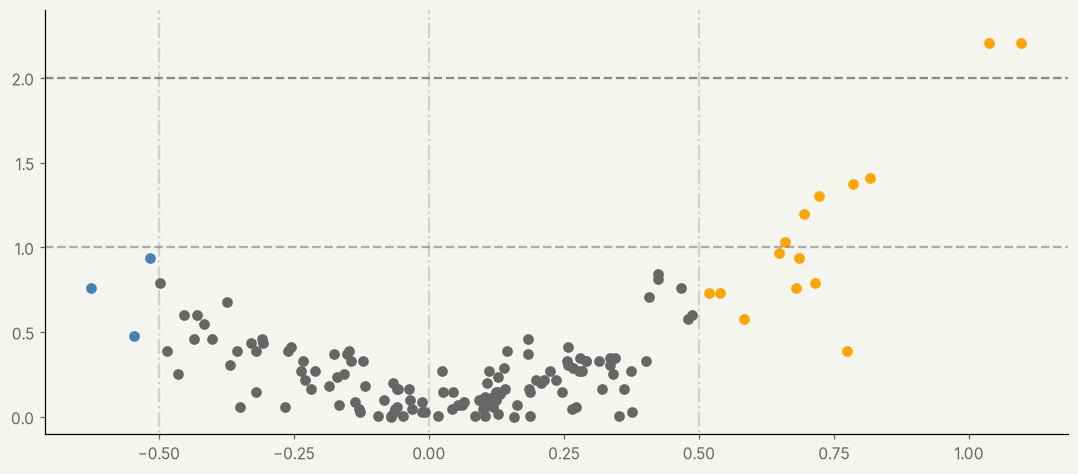

In [7]:
fig, ax = plt.subplots(figsize=(12, 5))

blue_mask = df_comparisons["cohen_d"] < -0.5
red_mask = df_comparisons["cohen_d"] > 0.5
gray_mask = ~(blue_mask | red_mask)

ax.scatter(df_comparisons.loc[gray_mask, "cohen_d"], df_comparisons.loc[gray_mask, "log_p"], color = SUPPORT_COLOR)
ax.scatter(df_comparisons.loc[blue_mask, "cohen_d"], df_comparisons.loc[blue_mask, "log_p"], color = "steelblue")
ax.scatter(df_comparisons.loc[red_mask, "cohen_d"], df_comparisons.loc[red_mask, "log_p"], color = "orange")

# ax.set_xlim(-1, 1)
ax.set_ylim(-0.1, 2.4)
ax.vlines([-0.5, 0, 0.5], ymin=-0.2, ymax=2.5, colors=SUPPORT_COLOR, alpha = 0.25, linestyles="-.")
ax.axhline(-np.log10(0.01), label = "p = 0.01", color=SUPPORT_COLOR, alpha = 0.75, linestyle="--")
ax.axhline(-np.log10(0.1), label = "p = 0.1", color=SUPPORT_COLOR, alpha = 0.5, linestyle="--")

plt.show()

In [23]:
# df_comparisons.loc[blue_mask | red_mask, :].sort_values(by="p")

In [22]:
from scipy.stats import wilcoxon

df_increase = df[df["Rest"] == 0].copy()
df_increase["PCE_calc"] = df_increase["PCE"].values
df_increase["PCE_rest"] = df.loc[df["Rest"] == 1, "PCE"].values # type: ignore
df_increase = df_increase.drop(columns = ["PCE"])

res = []

for ch in df_increase["Location"].unique():
    channel_mask = df_increase["Location"] == ch
    for band in df_increase["Band"].unique():
        band_mask = df_increase["Band"] == band
        
        for good_counters in [0, 1, 2]:
            counters_mask = df_increase["Count quality"] == good_counters
            if good_counters == 2:
                counters_mask = df_increase["Count quality"] < 2
                 
            df_case = df_increase.loc[channel_mask & band_mask & counters_mask, :]
            _, p = wilcoxon(df_case["PCE_calc"], df_case["PCE_rest"], alternative="greater")
            effect_size = cohen_d(df_case["PCE_calc"].values, df_case["PCE_rest"].values)

            res.append({
                    "Location" : ch,
                    "Band" : band,
                    "Counters" : "Good" if good_counters == 1 else "Poor" if good_counters == 0 else "All",
                    "p" : p,
                    "cohen_d" : effect_size
                    })

df_ttest = pd.DataFrame(res)
df_ttest["log_p"] = -np.log10(df_ttest["p"])
df_ttest.to_csv(RESULTS_FOLDER / "ttest.csv")
# df_ttest[df_ttest["p"] < 0.01].sort_values(by="cohen_d", ascending=False)

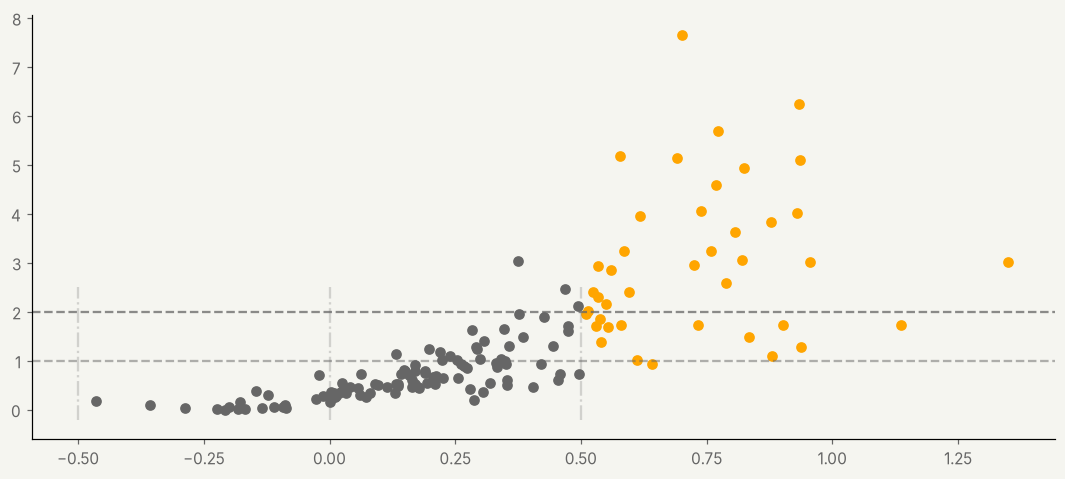

In [11]:
fig, ax = plt.subplots(figsize=(12, 5))

blue_mask = df_ttest["cohen_d"] < -0.5
red_mask = df_ttest["cohen_d"] > 0.5
gray_mask = ~(blue_mask | red_mask)

ax.scatter(df_ttest.loc[gray_mask, "cohen_d"], df_ttest.loc[gray_mask, "log_p"], color = SUPPORT_COLOR)
ax.scatter(df_ttest.loc[blue_mask, "cohen_d"], df_ttest.loc[blue_mask, "log_p"], color = "steelblue")
ax.scatter(df_ttest.loc[red_mask, "cohen_d"], df_ttest.loc[red_mask, "log_p"], color = "orange")

# ax.set_xlim(-1, 1)
# ax.set_ylim(-0.1, 2.4)
ax.vlines([-0.5, 0, 0.5], ymin=-0.2, ymax=2.5, colors=SUPPORT_COLOR, alpha = 0.25, linestyles="-.")
ax.axhline(-np.log10(0.01), label = "p = 0.01", color=SUPPORT_COLOR, alpha = 0.75, linestyle="--")
ax.axhline(-np.log10(0.1), label = "p = 0.1", color=SUPPORT_COLOR, alpha = 0.5, linestyle="--")

plt.show()

## Surrogate Signals

(19, 122000)


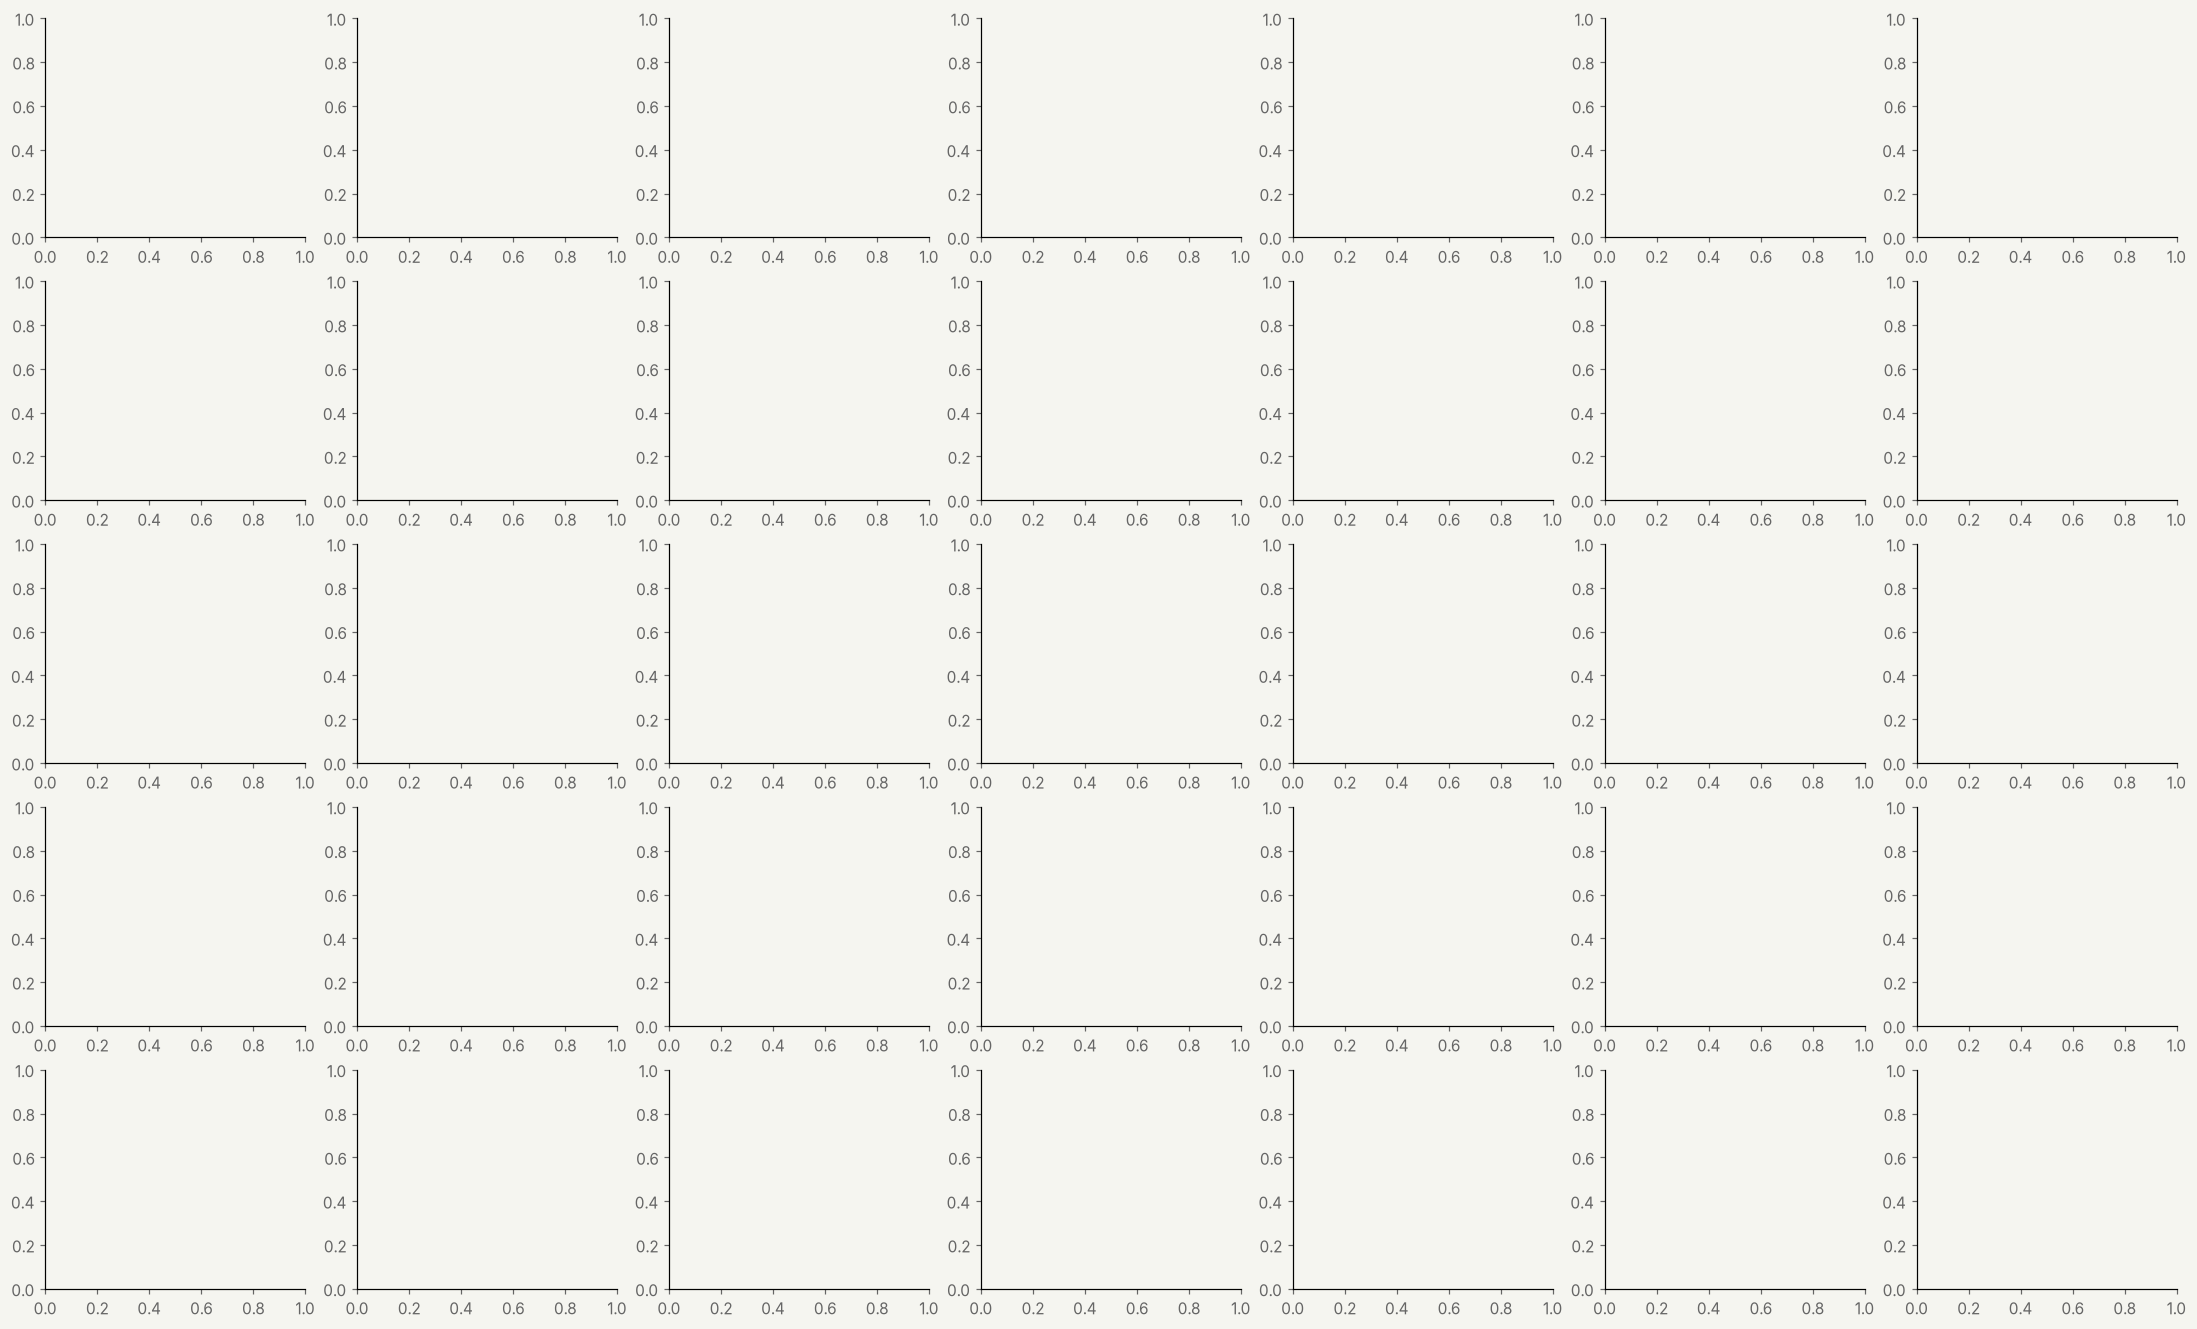

In [ ]:
from _functions import short_term_PCE, extract_band

fig, axes = plt.subplots(5, 7, figsize = (25, 15))

subjects = user_df["Subject"].unique()
channel = "ALL_CHANNELS"
band = "alpha"

for it in range(user_df["Subject"].nunique()):
    sbj = subjects[it]
    sbj_info = user_df.loc[user_df["Subject"] == sbj]
    
    # User's 31 rest phase is incomplete (1 minute instead of 3)
    if it == 31:
        continue
    if it > 31:
        it -= 1
        
    i = it // 7
    j = it % 7
    
    rest_raw = mne.io.read_raw_edf(DATA_FOLDER / f"{sbj}_1.edf", verbose=False)
    rest_np = np.array(rest_raw[["EEG " + ch for ch in CHANNELS[channel]]][0])
    rest_band = extract_band(rest_np, band, Fs)
    
    calc_raw = mne.io.read_raw_edf(DATA_FOLDER / f"{sbj}_2.edf", verbose=False)
    calc_np = np.array(calc_raw[["EEG " + ch for ch in CHANNELS[channel]]][0])
    calc_band = extract_band(calc_np, band, Fs)
    
    full = np.concat((rest_band, calc_band), axis = 1)
    
    timeline = short_term_PCE(full, Fs = Fs, window_size=10, overlap = 7.5)
    
    if j != 0:
        axes[i, j].spines["left"].set_visible(False)
        axes[i, j].set_yticks([])
        
    if i != 4:
        axes[i, j].spines["bottom"].set_visible(False)
        axes[i, j].set_xticks([])
    
    axes[i, j].plot(timeline)
    axes[i, j].set_ylim(0.1, 0.7)
    axes[i, j].plot(timeline)
    
    # axes[i, j].grid(axis = "y", color = SUPPORT_COLOR, alpha = 0.4)
    axes[i, j].axvline(18, color=SUPPORT_COLOR, alpha = 0.75, linestyle="--")

In [ ]:
del rest_raw, rest_np, rest_band
del calc_raw, calc_np, calc_band

In [47]:
from _functions import short_term_PCE, extract_band

channel = "ALL_CHANNELS"
band = "alpha"

sbj = "Subject31"
    
rest_raw = mne.io.read_raw_edf(DATA_FOLDER / f"{sbj}_1.edf", verbose = False)
rest_np = np.array(rest_raw[["EEG " + ch for ch in CHANNELS[channel]]][0])
print(rest_np.shape[1] / Fs)
rest_band = extract_band(rest_np, band, Fs)
timeline = short_term_PCE(rest_band, Fs = Fs, window_size=10)
print(len(timeline))
calc_raw = mne.io.read_raw_edf(DATA_FOLDER / f"{sbj}_2.edf", verbose = False)
calc_np = np.array(calc_raw[["EEG " + ch for ch in CHANNELS[channel]]][0])
print(calc_np.shape[1] / Fs)
calc_band = extract_band(rest_np, band, Fs)
timeline += short_term_PCE(rest_band, Fs = Fs, window_size=10)
print(len(timeline))


80.0
8
62.0
16
